# Đồ thị 03 Histogram phân bố serum creatinine

**Võ Minh Huy — 2311110117**

Đọc bản after_Python của đủ 299 hồ sơ. Chia khoảng rộng 0,5 mg/dL từ 0 đến 10; dùng trực tiếp serum_creatinine đã làm sạch. Không cần nhãn DEATH_EVENT và không thay đổi dữ liệu.


In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    import matplotlib.pyplot as plt

thu_muc = Path.cwd()
if thu_muc.name == "python":
    thu_muc = thu_muc.parent
du_lieu = pd.read_csv(thu_muc / "VoMinhHuy_Heart Failure Prediction_after_Python.csv")
creatinine = pd.to_numeric(du_lieu["serum_creatinine"], errors="raise")
if len(creatinine) != 299 or creatinine.isna().any() or not creatinine.between(0, 10, inclusive="left").all():
    raise ValueError("Cần đủ 299 giá trị creatinine trong [0, 10).")
thu_muc_kq = thu_muc / "ket_qua/21_do_thi/03_histogram_creatinine"
thu_muc_kq.mkdir(parents=True, exist_ok=True)
can = np.arange(0, 10.5, 0.5)
so_dem, _ = np.histogram(creatinine, bins=can)
assert so_dem.sum() == len(creatinine)
thong_ke = pd.DataFrame({"SoHoSo":[len(creatinine)], "Min":[creatinine.min()],
    "Q1":[creatinine.quantile(0.25)], "Median":[creatinine.median()],
    "Q3":[creatinine.quantile(0.75)], "Max":[creatinine.max()],
    "Mean":[creatinine.mean()], "DoRongKhoang":[0.5]})
thong_ke.round(2)


,SoHoSo,Min,Q1,Median,Q3,Max,Mean,DoRongKhoang
0,299,0.5,1.0,1.1,1.4,9.4,1.4,0.5


In [2]:
tan_suat = pd.DataFrame({"CanDuoi":can[:-1], "CanTren":can[1:], "SoHoSo":so_dem})
tan_suat["TyLePhanTram"] = (100 * tan_suat["SoHoSo"] / len(creatinine)).round(2)
tan_suat


,CanDuoi,CanTren,SoHoSo,TyLePhanTram
0,0.0,0.5,0,0.00
1,0.5,1.0,72,24.08
2,1.0,1.5,156,52.17
3,1.5,2.0,36,12.04
4,2.0,2.5,12,4.01
5,2.5,3.0,7,2.34
6,3.0,3.5,4,1.34
7,3.5,4.0,4,1.34
8,4.0,4.5,2,0.67
9,4.5,5.0,0,0.00


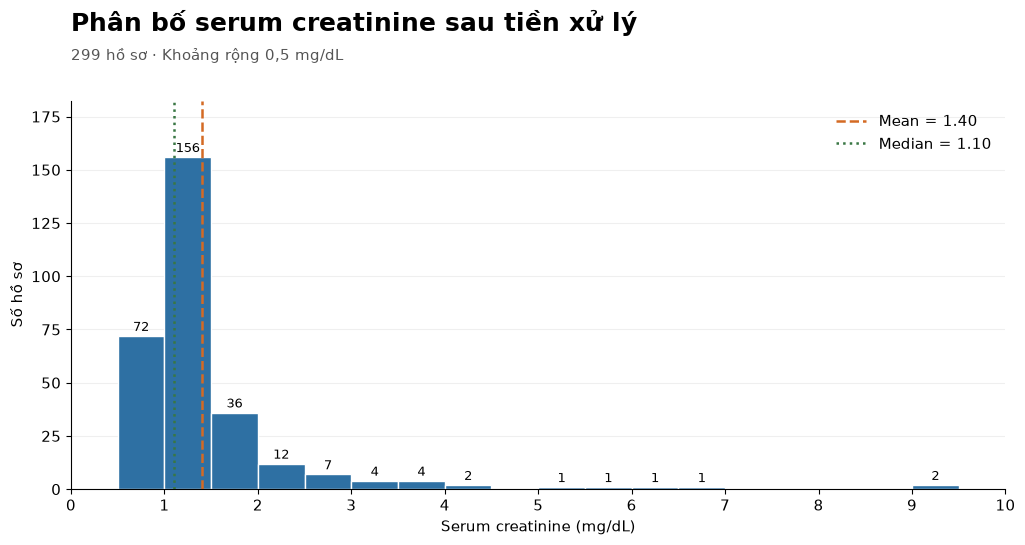

In [3]:
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11})
fig, ax = plt.subplots(figsize=(10.5, 5.8))
fig.subplots_adjust(top=0.82, bottom=0.15, left=0.09, right=0.98)
fig.text(0.09, 0.94, "Phân bố serum creatinine sau tiền xử lý", fontsize=18, weight="bold")
fig.text(0.09, 0.89, "299 hồ sơ · Khoảng rộng 0,5 mg/dL", color="#555555")
counts, _, _ = ax.hist(creatinine, bins=can, color="#2E70A3", edgecolor="white", linewidth=1)
assert np.array_equal(counts, so_dem)
ax.axvline(creatinine.mean(), color="#D46A24", linestyle="--", linewidth=1.8,
    label=f"Mean = {creatinine.mean():.2f}")
ax.axvline(creatinine.median(), color="#397744", linestyle=":", linewidth=1.8,
    label=f"Median = {creatinine.median():.2f}")
for left, n in zip(can[:-1], so_dem):
    if n:
        ax.text(left + 0.25, n + max(so_dem)*0.015, str(n), ha="center", fontsize=9)
ax.set(xlabel="Serum creatinine (mg/dL)", ylabel="Số hồ sơ", xlim=(0,10),
    ylim=(0, max(so_dem)*1.17))
ax.set_xticks(np.arange(0,11,1))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
fig.savefig(thu_muc_kq / "03_histogram_creatinine.png", dpi=300, bbox_inches="tight", facecolor="white")
thong_ke.to_csv(thu_muc_kq / "thong_ke_python.csv", index=False, encoding="utf-8-sig")
tan_suat.to_csv(thu_muc_kq / "tan_suat_python.csv", index=False, encoding="utf-8-sig")
plt.show()


## Nhận xét

Mean khoảng 1,40 mg/dL cao hơn median 1,10 mg/dL; phân bố có đuôi kéo dài về phía giá trị lớn. Histogram giữ toàn bộ các giá trị đến 9,4, không cắt đuôi để làm hình cân đối. Các giá trị lớn cần được xem trong bối cảnh dữ liệu, không tự động coi là lỗi hoặc xóa khỏi tập.

Đây là dữ liệu sau tiền xử lý, có cả giá trị creatinine đã điền ở N05. Độ rộng 0,5 mg/dL là lựa chọn để mô tả hình dạng phân bố; các khoảng không phải ngưỡng chẩn đoán.
